# **Objectifs de l'atelier**
Ce notebook permet de manipuler les outils de traitement d'images basiques permettant de traiter les images generiques et particulierement les images medicales.

Dans le cadre de ce premier atelier,  vous allez

*   decouvrir les differentes modalites d'imageries medicales
*   se familiariser avec les outils de manipulation d'images medicales

> *   lecture d'image medicales
*   sauvegarde d'images medicales
*   affichage d'images medicales

*   s'entrainer avec les outils permettant de degager les caracterisques des images medicales


Pour pouvoir faire les exercices de ce notebook vous devez au préalable vérifier que les librairies suivantes sont installées et les installer dans le cas contraire:

- numpy : bibliothèque pour les calculs scientifiques et mathématiques.
- opencv : bibliothèque de traitement d'images.
- imageio : bibliothèque de lecture/ecriture d'images.
- matplotlib : bibliothèque qui permet l'affichage de graphiques.
- os : bibliothèque dédiée aux besoins de gestion de fichiers et de dossiers.







# **Définition d'une image médicale et modalités**



une image médicale comme la matérialisation sous forme d’images d’information anatomique ou fonctionnelle in vivo de parties (organes, tissus, cellules) du corps humain [BIHAN 2018].

Ces images sont obtenues pour répondre à un besoin médical (question posée par un clinicien)

Il existe plusieurs modalités pour les images médicales, nous citons dans ce qui suit certains exemples (images IRM du cerveau, image echographique du rein et image endoscopique du larynx, etc)

<div>
<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSV5QjRqlhd4Dc6rFJo9T7J8XtDAinC06VX9IzRh_LB&s" width="200"/>
<img src="https://www.hug.ch/sites/interhug/files/structures/nephrologie/images/echographie.jpg" width="245" title="echography"/>
<img src="https://www.researchgate.net/publication/339702840/figure/fig5/AS:960119030435850@1605921623109/Normal-larynx-seen-during-transnasal-endoscopy-with-standard-distance-between-the-tip-of.jpg" width="270"/>
</div>


# **Images des cordes vocales**

L'enregistrement des images des cordes vocales se fait a l'aide d'un endoscope passant par la bouche ou bien le nez du patient dans le but d'enregistrer les mouvements des cordes vocales.

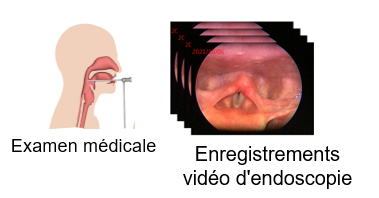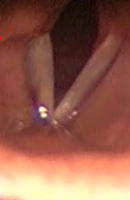

In [ ]:
# Cellule de configuration - exécuter en premier sur Colab
!pip install -q imageio

import os

DATA_DIR = 'Data_At1/Data_At1'  # adapter ce chemin si nécessaire

# Auto-détection du dossier si le précédent n'existe pas
if not os.path.isfile(os.path.join(DATA_DIR, 'frame856.png')):
    for cand in ['Data_At1', 'data', '.', '/content/Data_At1/Data_At1']:
        if os.path.isfile(os.path.join(cand, 'frame856.png')):
            DATA_DIR = cand
            break
print(f'Dossier de données utilisé : {DATA_DIR}')


# **Exercice 1 : Lecture d'image et extraction de caracteristiques**

L'objectif de cet exercice est de lire et afficher les valeurs de niveaux de gris d'une image classique au format 'png' et contenant des données médicales (cordes vocales)

1.a) En utilisant la librairie opencv, charger l'image 'frame856.png' et affichez les valeurs des intensités de l'image couleur.


In [ ]:
import cv2
import numpy as np

img_color = cv2.imread(os.path.join(DATA_DIR, 'frame856.png'))
print('Forme de l\'image couleur :', img_color.shape)
print('Type :', img_color.dtype)
print('Valeurs des intensités (image couleur BGR) :')
print(img_color)


1.b) En utilisant la librairie opencv, charger l'image 'frame856.png' et affichez les valeurs des intensités contenues de l'image en niveau de gris.


In [ ]:
img_gray = cv2.imread(os.path.join(DATA_DIR, 'frame856.png'), cv2.IMREAD_GRAYSCALE)
print('Forme de l\'image en niveaux de gris :', img_gray.shape)
print('Type :', img_gray.dtype)
print('Valeurs des intensités (image en niveaux de gris) :')
print(img_gray)


2.a) A l'aide de la librairie matplotlib, visualisez l'image en niveaux de gris.


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(img_gray, cmap='gray')
plt.title('Image en niveaux de gris (cv2)')
plt.axis('off')
plt.show()


*2*.b) A l'aide des librairies imageio et matplotlib, rechargez et affichez de nouveau l'image. Que remarquez vous ?


In [ ]:
import imageio.v2 as imageio

img_gray_imageio = imageio.imread(os.path.join(DATA_DIR, 'frame856.png'))
print('Type lu avec imageio :', type(img_gray_imageio))
print('Forme :', img_gray_imageio.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img_gray_imageio, cmap='gray')
plt.title('Image en niveaux de gris (imageio)')
plt.axis('off')
plt.show()

# Remarque : imageio lit le PNG en conservant l'ordre RGB tandis que cv2 convertit
# déjà vers les niveaux de gris. Le résultat visuel est identique, mais les valeurs
# et le type de tableau peuvent légèrement différer (uint8 vs float, etc.).


3) Affichez  la taille en pixels, l'hauteur et la largeur, la dimension ainsi que la valeur maximale de l'image.


In [ ]:
print('Taille totale (nombre de pixels) :', img_gray.size)
print('Hauteur :', img_gray.shape[0])
print('Largeur :', img_gray.shape[1])
print('Dimension du tableau :', img_gray.ndim)
print('Valeur maximale :', img_gray.max())


4) Affichez la taille en mémoire de l'image à l'aide de la librairie os.


In [ ]:
import os

file_path = os.path.join(DATA_DIR, 'frame856.png')
size_bytes = os.path.getsize(file_path)
print(f'Taille du fichier sur le disque : {size_bytes} octets')
print(f'Taille en Ko : {size_bytes / 1024:.2f} Ko')
print(f'Taille en Mo : {size_bytes / (1024 * 1024):.2f} Mo')


5) A l'aide de la librairie matplotlib, affichez l'histogramme de l'image en niveaux de gris


In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(img_gray.flatten(), bins=256, range=(0, 256), color='gray', edgecolor='black')
plt.title('Histogramme de l\'image en niveaux de gris')
plt.xlabel('Niveau de gris')
plt.ylabel('Nombre de pixels')
plt.grid(alpha=0.3)
plt.show()


6) A l'aide de la librairie matplotlib, affichez dans la meme figure les trois couches couleur de l'image précedement lue ainsi que l'histogramme de chacune. Interpretez.


In [ ]:
# opencv lit en BGR -> on convertit en RGB pour l'affichage matplotlib
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

axes[0, 0].imshow(img_rgb[:, :, 0], cmap='Reds')
axes[0, 0].set_title('Canal Rouge'); axes[0, 0].axis('off')
axes[0, 1].imshow(img_rgb[:, :, 1], cmap='Greens')
axes[0, 1].set_title('Canal Vert'); axes[0, 1].axis('off')
axes[0, 2].imshow(img_rgb[:, :, 2], cmap='Blues')
axes[0, 2].set_title('Canal Bleu'); axes[0, 2].axis('off')
axes[0, 3].imshow(img_rgb)
axes[0, 3].set_title('Image RGB originale'); axes[0, 3].axis('off')

axes[1, 0].hist(img_rgb[:, :, 0].flatten(), bins=256, range=(0, 256), color='red')
axes[1, 0].set_title('Histogramme Rouge')
axes[1, 1].hist(img_rgb[:, :, 1].flatten(), bins=256, range=(0, 256), color='green')
axes[1, 1].set_title('Histogramme Vert')
axes[1, 2].hist(img_rgb[:, :, 2].flatten(), bins=256, range=(0, 256), color='blue')
axes[1, 2].set_title('Histogramme Bleu')
axes[1, 3].hist(img_gray.flatten(), bins=256, range=(0, 256), color='gray')
axes[1, 3].set_title('Histogramme niveaux de gris')

for ax in axes[1, :]:
    ax.set_xlabel('Niveau')
    ax.set_ylabel('Nombre de pixels')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Interprétation : les trois canaux sont visuellement proches car l'image est globalement
# grisâtre (muqueuse des cordes vocales). Le canal rouge est légèrement dominant
# (tissu vascularisé), ce qui est cohérent avec l'histogramme décalé vers les valeurs
# élevées sur les tons chair.


7) Affichez les valeurs du pixel de coordonnees 100 et 50 dans les trois couches couleur


In [ ]:
x, y = 100, 50  # convention matplotlib : x = colonne, y = ligne
print(f'Valeurs du pixel aux coordonnées (y={y}, x={x}) :')
print(f'  Canal Rouge  : {img_rgb[y, x, 0]}')
print(f'  Canal Vert   : {img_rgb[y, x, 1]}')
print(f'  Canal Bleu   : {img_rgb[y, x, 2]}')


# **Exercice 2 : Lecture de video et extraction de frames**

1) En utilisant la librairie opencv, lisez la video 'patient4.mp4'.


In [ ]:
video_path = os.path.join(DATA_DIR, 'patient4.mp4')
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise IOError(f'Impossible d\'ouvrir la vidéo : {video_path}')

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count / fps if fps else 0

print('Vidéo ouverte avec succès.')
print(f'  FPS            : {fps:.2f}')
print(f'  Nombre frames  : {frame_count}')
print(f'  Résolution     : {width} x {height}')
print(f'  Durée (s)      : {duration:.2f}')

cap.release()


2) En utilisant la librairie opencv, lisez la video 'patient4.mp4'.


In [ ]:
# Extraction et sauvegarde de tous les frames dans une liste
cap = cv2.VideoCapture(video_path)
frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)
cap.release()

print(f'Frames extraits : {len(frames)}')

# Affichage de quelques frames répartis sur la vidéo
if len(frames) > 0:
    indices = [0,
               len(frames) // 4,
               len(frames) // 2,
               3 * len(frames) // 4,
               len(frames) - 1]
    indices = [min(i, len(frames) - 1) for i in indices]
    fig, axes = plt.subplots(1, len(indices), figsize=(20, 4))
    if len(indices) == 1:
        axes = [axes]
    for ax, idx in zip(axes, indices):
        ax.imshow(cv2.cvtColor(frames[idx], cv2.COLOR_BGR2RGB))
        ax.set_title(f'Frame {idx}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()


# **Exercice 3 : Supperpostion de masque sur une image**

---



1) En utilisant la librairie imageio, lisez les deux frames 'frame442.png' et son masque 'frame442_glottis.png', En utilisant la librairie opencv supperposez le masque sur l'image originale.


In [ ]:
# Lecture de l'image et du masque avec imageio
img = imageio.imread(os.path.join(DATA_DIR, 'frame442.png'))
mask = imageio.imread(os.path.join(DATA_DIR, 'frame442_glottis.png'))

print('Image originale - forme :', img.shape, 'dtype :', img.dtype)
print('Masque        - forme :', mask.shape, 'dtype :', mask.dtype)
print('Valeurs uniques du masque :', np.unique(mask))

# Si le masque est en niveaux de gris (2D), on le transforme en masque booléen
mask_bool = mask > 0 if mask.ndim == 2 else mask[..., 0] > 0

# Superposition : on colore en rouge la zone du masque avec opencv (BGR)
img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
overlay = img_bgr.copy()
overlay[mask_bool] = [0, 0, 255]  # rouge en BGR
overlay_bgr = overlay


2) Affichez sur la meme figure les trois images : l'originale, le mask et l'image superposee


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img)
axes[0].set_title('Image originale')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Masque du glottis')
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB))
axes[2].set_title('Image superposée (masque en rouge)')
axes[2].axis('off')

plt.tight_layout()
plt.show()
